# Validade externa: os 16 rankings e a taxa de internações por DRSAI

Este notebook aplica o protocolo da seção 7 do `docs/Log de decisoes.md`, congelado em 9 nov. 2026, antes de qualquer cálculo com a DRSAI. A DRSAI não entra em nenhum ranking; ela só avalia os rankings prontos.

1. Amostra comum: os municípios da amostra com taxa de DRSAI válida (taxa 0,00 é ausente).
2. Spearman ρ entre a pontuação de cada ranking e a taxa. Espera-se ρ negativo: melhor saneamento, menos internações.
3. Δρ entre pares de rankings, com intervalo de 95% por bootstrap percentil (5.000 reamostragens de municípios, semente 20261109) e o teste de Steiger (1980) como conferência.
4. ρ parcial controlando por UF e porte; ρ dentro de BA, CE, PE, RN e PB e dentro de cada porte.
5. Repetição sem os 5% de taxas mais altas.

Linguagem de associação: um ρ mais negativo quer dizer que a ordenação é mais coerente com as internações, e não que o método reduz internações.

Entrada: `planilhas/Relatorio ABES 2026 NE.ods`, que traz os cinco indicadores e a taxa de DRSAI dos 505 municípios. Os 16 rankings são recalculados com as funções de `mcda.py`, as mesmas do notebook 01. O notebook não grava arquivos.

In [1]:
from pathlib import Path

import numpy as np
import pandas as pd
from scipy import stats
import matplotlib.pyplot as plt

import mcda

RAIZ = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "dados").is_dir())
SEMENTE = 20261109
N_BOOT = 5000
ESTADOS = ["BA", "CE", "PE", "RN", "PB"]
ABES = "Soma ponderada | Pesos iguais"

ORDEM = [f"{m} | {e}" for m in mcda.METODOS for e in mcda.ESQUEMAS]

## 1. Taxa de DRSAI e amostra comum

In [2]:
base = mcda.ler_base(RAIZ)
pont = mcda.rankings(base[mcda.CRITERIOS].to_numpy(float))
rk = pd.concat([base[["Município", "UF", "Porte"]], pont.add_prefix("pontuação | ")], axis=1)
rk["DRSAI"] = base["Taxa de Internações por DRSAI"]
assert rk["DRSAI"].notna().all()

val = rk[rk["DRSAI"] > 0].reset_index(drop=True)
print(len(rk), "municípios na amostra;", (rk["DRSAI"] == 0).sum(), "com taxa 0,00 (ausente);", len(val), "com taxa válida")
display(val.groupby("UF").size().rename("válidos").to_frame().T)
display(val.groupby("Porte").size().rename("válidos").to_frame().T)
val["DRSAI"].describe().round(2)

505 municípios na amostra; 145 com taxa 0,00 (ausente); 360 com taxa válida


UF,AL,BA,CE,MA,PB,PE,PI,RN,SE
válidos,12,121,84,9,27,62,2,35,8


Porte,Grande porte,Pequeno e médio porte
válidos,57,303


count     360.00
mean      166.01
std       413.47
min         0.37
25%        21.14
50%        50.72
75%       133.22
max      4873.73
Name: DRSAI, dtype: float64

## 2. Associação de cada ranking com a DRSAI

Intervalo de 95% de cada ρ por bootstrap percentil. As mesmas reamostragens servem para os Δρ da seção 3.

In [3]:
PONT = val[[f"pontuação | {c}" for c in ORDEM]].to_numpy()
y = val["DRSAI"].to_numpy()
n = len(y)

def spearman_cols(M, v):
    R = np.apply_along_axis(stats.rankdata, 0, M)
    r = stats.rankdata(v)
    R = (R - R.mean(0)) / R.std(0)
    r = (r - r.mean()) / r.std()
    return (R * r[:, None]).mean(0)

rho = spearman_cols(PONT, y)
rng = np.random.default_rng(SEMENTE)
idx = rng.integers(0, n, size=(N_BOOT, n))
boot = np.array([spearman_cols(PONT[i], y[i]) for i in idx])  # N_BOOT × 16

res = pd.DataFrame({
    "Método": [c.split(" | ")[0] for c in ORDEM],
    "Pesos": [c.split(" | ")[1] for c in ORDEM],
    "ρ": rho,
    "IC 2,5%": np.percentile(boot, 2.5, axis=0),
    "IC 97,5%": np.percentile(boot, 97.5, axis=0),
    "p": [stats.spearmanr(PONT[:, k], y)[1] for k in range(16)],
}, index=ORDEM)
res.sort_values("ρ").round(4)

,Método,Pesos,ρ,"IC 2,5%","IC 97,5%",p
VIKOR | Pesos iguais,VIKOR,Pesos iguais,-0.2296,-0.3248,-0.1313,0.0000
VIKOR | CRITIC,VIKOR,CRITIC,-0.2278,-0.3229,-0.1316,0.0000
Soma ponderada | CRITIC,Soma ponderada,CRITIC,-0.2269,-0.3224,-0.1303,0.0000
PROMETHEE II | CRITIC,PROMETHEE II,CRITIC,-0.2240,-0.3187,-0.1265,0.0000
Soma ponderada | Pesos iguais,Soma ponderada,Pesos iguais,-0.2179,-0.3134,-0.1206,0.0000
VIKOR | AHP Gaussiano,VIKOR,AHP Gaussiano,-0.2103,-0.3037,-0.1129,0.0001
TOPSIS | CRITIC,TOPSIS,CRITIC,-0.2058,-0.3006,-0.1093,0.0001
PROMETHEE II | Pesos iguais,PROMETHEE II,Pesos iguais,-0.1873,-0.2832,-0.0893,0.0004
PROMETHEE II | AHP Gaussiano,PROMETHEE II,AHP Gaussiano,-0.1775,-0.2729,-0.0801,0.0007
Soma ponderada | AHP Gaussiano,Soma ponderada,AHP Gaussiano,-0.1679,-0.2632,-0.0693,0.0014


In [4]:
tabela = res.pivot(index="Método", columns="Pesos", values="ρ").loc[mcda.METODOS, mcda.ESQUEMAS]
tabela["Média do método"] = tabela.mean(axis=1)
tabela.loc["Média dos pesos"] = tabela.mean(axis=0)
tabela.round(3)

Pesos,Pesos iguais,CRITIC,AHP Gaussiano,AHP clássico,Média do método
Método,,,,,
Soma ponderada,-0.218,-0.227,-0.168,-0.151,-0.191
TOPSIS,-0.137,-0.206,-0.141,-0.114,-0.149
VIKOR,-0.230,-0.228,-0.210,-0.150,-0.204
PROMETHEE II,-0.187,-0.224,-0.177,-0.152,-0.185
Média dos pesos,-0.193,-0.221,-0.174,-0.142,-0.182


**F1.** Os 16 ρ com intervalo bootstrap, agrupados por método (na ordem do grau de compensação) e marcados por esquema de pesos.

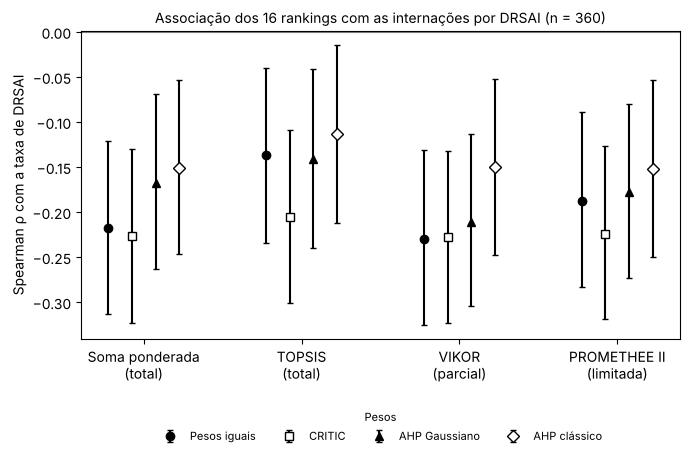

In [5]:
fig, ax = plt.subplots(figsize=(7, 4.8))
marcas = {"Pesos iguais": "o", "CRITIC": "s", "AHP Gaussiano": "^", "AHP clássico": "D"}
for i, m in enumerate(mcda.METODOS):
    for j, e in enumerate(mcda.ESQUEMAS):
        r = res.loc[f"{m} | {e}"]
        x = i + (j - 1.5) * 0.15
        ax.errorbar(x, r["ρ"], yerr=[[r["ρ"] - r["IC 2,5%"]], [r["IC 97,5%"] - r["ρ"]]],
                    fmt=marcas[e], color="black", mfc="white" if j % 2 else "black", capsize=2,
                    label=e if i == 0 else None)
ax.axhline(0, color="grey", lw=0.8)
ax.set_xticks(range(4), ["Soma ponderada\n(total)", "TOPSIS\n(total)", "VIKOR\n(parcial)", "PROMETHEE II\n(limitada)"])
ax.set_ylabel("Spearman ρ com a taxa de DRSAI")
ax.legend(title="Pesos", fontsize=8, title_fontsize=8, ncol=4, loc="upper center", bbox_to_anchor=(0.5, -0.2), frameon=False)
ax.set_title(f"Associação dos 16 rankings com as internações por DRSAI (n = {n})", fontsize=10)
fig.tight_layout()

## 3. Diferenças entre rankings (Δρ)

Δρ = ρ(A) − ρ(B). Como a associação esperada é negativa, Δρ < 0 quer dizer que A se associa mais fortemente à DRSAI que B. O intervalo vem das mesmas 5.000 reamostragens. O teste de Steiger (1980) compara duas correlações dependentes que compartilham a DRSAI, levando em conta a correlação entre os dois rankings; é aplicado aqui aos ρ de Spearman, como aproximação.

In [6]:
RHO_RK = pd.DataFrame(PONT, columns=ORDEM).corr("spearman").to_numpy()

def steiger(r1, r2, r12, n):
    z1, z2 = np.arctanh(r1), np.arctanh(r2)
    rm = (r1 + r2) / 2
    psi = r12 * (1 - 2 * rm**2) - 0.5 * rm**2 * (1 - 2 * rm**2 - r12**2)
    c = psi / (1 - rm**2) ** 2
    z = (z1 - z2) * np.sqrt(n - 3) / np.sqrt(2 - 2 * c)
    return z, 2 * stats.norm.sf(abs(z))

pares = []
for a in range(16):
    for b in range(a + 1, 16):
        d = boot[:, a] - boot[:, b]
        z, p = steiger(rho[a], rho[b], RHO_RK[a, b], n)
        pares.append({"A": ORDEM[a], "B": ORDEM[b], "Δρ": rho[a] - rho[b],
                      "IC 2,5%": np.percentile(d, 2.5), "IC 97,5%": np.percentile(d, 97.5),
                      "ρ entre A e B": RHO_RK[a, b], "Steiger z": z, "Steiger p": p})
pares = pd.DataFrame(pares)
pares["IC exclui 0"] = (pares["IC 2,5%"] > 0) | (pares["IC 97,5%"] < 0)
print(f"{pares['IC exclui 0'].sum()} dos {len(pares)} pares têm IC de Δρ que exclui zero;",
      f"{(pares['Steiger p'] < 0.05).sum()} têm p < 0,05 no teste de Steiger")

51 dos 120 pares têm IC de Δρ que exclui zero; 52 têm p < 0,05 no teste de Steiger


**Cada ranking contra o ABES** (soma ponderada com pesos iguais). Δρ = ρ(ranking) − ρ(ABES).

In [7]:
def contra(ref):
    t = pares[(pares["A"] == ref) | (pares["B"] == ref)].copy()
    inv = t["A"] == ref
    t["Ranking"] = np.where(inv, t["B"], t["A"])
    t.loc[inv, ["Δρ", "IC 2,5%", "IC 97,5%", "Steiger z"]] = -t.loc[inv, ["Δρ", "IC 97,5%", "IC 2,5%", "Steiger z"]].to_numpy()
    return t.set_index("Ranking")[["Δρ", "IC 2,5%", "IC 97,5%", "ρ entre A e B", "Steiger p", "IC exclui 0"]].sort_values("Δρ")

contra(ABES).round(4)

,Δρ,"IC 2,5%","IC 97,5%",ρ entre A e B,Steiger p,IC exclui 0
Ranking,,,,,,
VIKOR | Pesos iguais,-0.0117,-0.0323,0.0079,0.9803,0.2521,False
VIKOR | CRITIC,-0.0099,-0.0423,0.0224,0.9473,0.5548,False
Soma ponderada | CRITIC,-0.0091,-0.0343,0.0152,0.9684,0.4846,False
PROMETHEE II | CRITIC,-0.0061,-0.0198,0.0077,0.9911,0.3772,False
VIKOR | AHP Gaussiano,0.0075,-0.0341,0.0494,0.9066,0.7354,False
TOPSIS | CRITIC,0.0121,-0.0207,0.0455,0.9446,0.4829,False
PROMETHEE II | Pesos iguais,0.0306,0.0009,0.0614,0.9586,0.0403,True
PROMETHEE II | AHP Gaussiano,0.0404,0.0103,0.0715,0.9605,0.0056,True
Soma ponderada | AHP Gaussiano,0.0499,0.0040,0.0969,0.9003,0.0311,True


In [8]:
melhor = res["ρ"].idxmin()
print("Ranking com a associação mais forte:", melhor)
contra(melhor).round(4)

Ranking com a associação mais forte: VIKOR | Pesos iguais


,Δρ,"IC 2,5%","IC 97,5%",ρ entre A e B,Steiger p,IC exclui 0
Ranking,,,,,,
VIKOR | CRITIC,0.0018,-0.0211,0.0245,0.9727,0.8780,False
Soma ponderada | CRITIC,0.0027,-0.0204,0.0252,0.9725,0.8252,False
PROMETHEE II | CRITIC,0.0057,-0.0122,0.0244,0.9818,0.5650,False
Soma ponderada | Pesos iguais,0.0117,-0.0079,0.0323,0.9803,0.2521,False
VIKOR | AHP Gaussiano,0.0193,-0.0200,0.0577,0.9321,0.3107,False
TOPSIS | CRITIC,0.0238,-0.0054,0.0533,0.9570,0.1160,False
PROMETHEE II | Pesos iguais,0.0423,0.0019,0.0845,0.9207,0.0401,True
PROMETHEE II | AHP Gaussiano,0.0521,0.0158,0.0894,0.9435,0.0027,True
Soma ponderada | AHP Gaussiano,0.0617,0.0130,0.1117,0.8959,0.0091,True


**Os pares cujo intervalo exclui zero.**

In [9]:
pares[pares["IC exclui 0"]].sort_values("Δρ").round(4)

,A,B,Δρ,"IC 2,5%","IC 97,5%",ρ entre A e B,Steiger z,Steiger p,IC exclui 0
20,Soma ponderada | CRITIC,TOPSIS | AHP clássico,-0.1134,-0.2031,-0.0223,0.5803,-2.3839,0.0171,True
6,Soma ponderada | Pesos iguais,TOPSIS | AHP clássico,-0.1043,-0.1773,-0.0305,0.7352,-2.7552,0.0059,True
17,Soma ponderada | CRITIC,TOPSIS | Pesos iguais,-0.0899,-0.1468,-0.0364,0.8587,-3.2563,0.0011,True
19,Soma ponderada | CRITIC,TOPSIS | AHP Gaussiano,-0.0859,-0.1512,-0.0244,0.8244,-2.7921,0.0052,True
3,Soma ponderada | Pesos iguais,TOPSIS | Pesos iguais,-0.0808,-0.1232,-0.0400,0.9267,-4.0588,0.0000,True
94,VIKOR | Pesos iguais,VIKOR | AHP clássico,-0.0797,-0.1571,-0.0043,0.6962,-1.9741,0.0484,True
5,Soma ponderada | Pesos iguais,TOPSIS | AHP Gaussiano,-0.0768,-0.1358,-0.0203,0.8625,-2.8179,0.0048,True
16,Soma ponderada | CRITIC,Soma ponderada | AHP clássico,-0.0761,-0.1459,-0.0090,0.7733,-2.1794,0.0293,True
2,Soma ponderada | Pesos iguais,Soma ponderada | AHP clássico,-0.0670,-0.1164,-0.0203,0.8952,-2.8171,0.0048,True
65,TOPSIS | CRITIC,TOPSIS | AHP Gaussiano,-0.0647,-0.1198,-0.0136,0.8858,-2.6020,0.0093,True


## 4. Efeito dos pesos e do método

Médias de Δρ por bootstrap: cada esquema de pesos contra a média dos outros (mantido o método), e cada método contra a média dos outros (mantidos os pesos). Mostra qual dos dois fatores move mais a associação.

In [10]:
B = boot.reshape(N_BOOT, 4, 4)  # [boot, método, pesos], na ordem de ORDEM
R = rho.reshape(4, 4)
def efeito(eixo, nomes):
    linhas = []
    for k, nome in enumerate(nomes):
        sel = np.take(B, k, axis=eixo + 1).mean(1)
        resto = np.delete(B, k, axis=eixo + 1).mean((1, 2))
        d = sel - resto
        linhas.append({"": nome, "ρ médio": np.take(R, k, axis=eixo).mean(),
                       "Δρ contra os demais": (np.take(R, k, axis=eixo).mean() - np.delete(R, k, axis=eixo).mean()),
                       "IC 2,5%": np.percentile(d, 2.5), "IC 97,5%": np.percentile(d, 97.5)})
    return pd.DataFrame(linhas).set_index("")
print("Métodos (média sobre os quatro esquemas de pesos)")
display(efeito(0, mcda.METODOS).round(4))
print("Esquemas de pesos (média sobre os quatro métodos)")
display(efeito(1, mcda.ESQUEMAS).round(4))

Métodos (média sobre os quatro esquemas de pesos)


,ρ médio,Δρ contra os demais,"IC 2,5%","IC 97,5%"
,,,,
Soma ponderada,-0.1909,-0.0113,-0.0222,0.0001
TOPSIS,-0.1494,0.0441,0.0207,0.0676
VIKOR,-0.2044,-0.0293,-0.0493,-0.0092
PROMETHEE II,-0.1852,-0.0036,-0.0247,0.0169


Esquemas de pesos (média sobre os quatro métodos)


,ρ médio,Δρ contra os demais,"IC 2,5%","IC 97,5%"
,,,,
Pesos iguais,-0.1930,-0.0140,-0.0269,-0.0018
CRITIC,-0.2211,-0.0515,-0.0957,-0.0098
AHP Gaussiano,-0.1742,0.0110,-0.0347,0.0570
AHP clássico,-0.1416,0.0545,-0.0153,0.1226


## 5. Controle mínimo por UF e porte

**ρ parcial.** Os postos da pontuação e da taxa são regredidos sobre variáveis indicadoras de UF e de porte, e o ρ parcial é a correlação entre os resíduos. **Dentro dos grupos.** Spearman nos estados com amostra suficiente e em cada porte; AL, MA, SE e PI só entram na análise conjunta.

In [11]:
D = pd.get_dummies(val[["UF", "Porte"]], drop_first=True).astype(float)
D.insert(0, "const", 1.0)
Dm = D.to_numpy()
def residuo(v):
    beta, *_ = np.linalg.lstsq(Dm, v, rcond=None)
    return v - Dm @ beta
ry = residuo(stats.rankdata(y))
parcial = [np.corrcoef(residuo(stats.rankdata(PONT[:, k])), ry)[0, 1] for k in range(16)]

grupos = {"Todos": np.ones(n, bool)}
grupos |= {uf: (val["UF"] == uf).to_numpy() for uf in ESTADOS}
grupos |= {p: (val["Porte"] == p).to_numpy() for p in sorted(val["Porte"].unique())}
dentro = pd.DataFrame({g: [stats.spearmanr(PONT[s, k], y[s])[0] for k in range(16)] for g, s in grupos.items()}, index=ORDEM)
dentro.insert(1, "Parcial UF + porte", parcial)
n_grupo = pd.Series({g: s.sum() for g, s in grupos.items()}, name="n")
display(n_grupo.to_frame().T)
dentro.round(3)

,Todos,BA,CE,PE,RN,PB,Grande porte,Pequeno e médio porte
n,360,121,84,62,35,27,57,303


,Todos,Parcial UF + porte,BA,CE,PE,RN,PB,Grande porte,Pequeno e médio porte
Soma ponderada | Pesos iguais,-0.218,-0.125,-0.271,0.048,-0.209,-0.050,-0.234,0.004,-0.145
Soma ponderada | CRITIC,-0.227,-0.138,-0.258,0.020,-0.220,-0.129,-0.224,0.017,-0.160
Soma ponderada | AHP Gaussiano,-0.168,-0.080,-0.182,-0.008,-0.177,0.009,-0.134,-0.058,-0.099
Soma ponderada | AHP clássico,-0.151,-0.063,-0.242,0.099,-0.186,0.021,-0.247,0.009,-0.073
TOPSIS | Pesos iguais,-0.137,-0.047,-0.173,0.056,-0.154,0.067,-0.187,-0.024,-0.064
TOPSIS | CRITIC,-0.206,-0.115,-0.203,0.010,-0.181,-0.039,-0.139,-0.031,-0.137
TOPSIS | AHP Gaussiano,-0.141,-0.059,-0.149,-0.003,-0.167,0.050,-0.103,-0.064,-0.075
TOPSIS | AHP clássico,-0.114,-0.041,-0.264,0.153,-0.160,0.041,-0.218,0.006,-0.038
VIKOR | Pesos iguais,-0.230,-0.138,-0.269,0.035,-0.243,-0.131,-0.150,-0.023,-0.156
VIKOR | CRITIC,-0.228,-0.140,-0.252,0.011,-0.224,-0.151,-0.141,-0.029,-0.161


In [12]:
posto = dentro.rank(axis=0, method="min").astype(int)  # 1 = associação mais forte (ρ mais negativo)
print("Posição de cada ranking (1 = ρ mais negativo) em cada análise")
posto

Posição de cada ranking (1 = ρ mais negativo) em cada análise


,Todos,Parcial UF + porte,BA,CE,PE,RN,PB,Grande porte,Pequeno e médio porte
Soma ponderada | Pesos iguais,5,5,4,10,4,8,6,10,5
Soma ponderada | CRITIC,3,3,8,6,3,3,7,14,2
Soma ponderada | AHP Gaussiano,10,10,14,2,8,11,15,3,10
Soma ponderada | AHP clássico,12,13,10,13,6,13,4,12,12
TOPSIS | Pesos iguais,15,15,15,11,14,16,10,7,15
TOPSIS | CRITIC,7,7,13,4,7,9,14,4,7
TOPSIS | AHP Gaussiano,14,14,16,3,10,15,16,1,11
TOPSIS | AHP clássico,16,16,7,16,13,14,8,11,16
VIKOR | Pesos iguais,1,2,6,8,1,2,12,8,3
VIKOR | CRITIC,2,1,9,5,2,1,13,5,1


## 6. Sem os 5% de taxas mais altas

In [13]:
corte = np.percentile(y, 95)
s = y <= corte
sem_ext = pd.DataFrame({"ρ (todos)": rho, "ρ sem os 5% mais altos": [stats.spearmanr(PONT[s, k], y[s])[0] for k in range(16)]}, index=ORDEM)
print(f"Corte: {corte:.2f}; ficam {s.sum()} municípios")
sem_ext.sort_values("ρ sem os 5% mais altos").round(4)

Corte: 639.82; ficam 342 municípios


,ρ (todos),ρ sem os 5% mais altos
VIKOR | Pesos iguais,-0.2296,-0.2254
Soma ponderada | Pesos iguais,-0.2179,-0.2179
Soma ponderada | CRITIC,-0.2269,-0.2163
PROMETHEE II | CRITIC,-0.2240,-0.2159
VIKOR | CRITIC,-0.2278,-0.2149
VIKOR | AHP Gaussiano,-0.2103,-0.2081
TOPSIS | CRITIC,-0.2058,-0.2019
PROMETHEE II | Pesos iguais,-0.1873,-0.1933
PROMETHEE II | AHP Gaussiano,-0.1775,-0.1815
Soma ponderada | AHP Gaussiano,-0.1679,-0.1769
